# 00 Dataset EDA: ICBHI 2017, KAUH and the replay set

Data used by the project (tier 0). ICBHI: 920 recordings, 126 patients, 4 devices, annotated breath cycles (4-class:
normal, crackle, wheeze, both); official 60/40 recording split (`official_split.txt`). KAUH: 112 patients x 3 vendor filters
(Bell, Diaphragm, Extended), recording-level labels. Replay: 20 ICBHI recordings played through a speaker and re-recorded by a
phone and an electret microphone. Figures: `outputs/figures/eda/`, tables: `outputs/analysis/eda/`.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/common.py
sys.path.insert(0, str(Path.cwd().parent))   # repository root for src.*
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from common import *
pd.set_option('display.precision', 2); pd.set_option('display.width', 160)
from src.processing.icbhi import cycle_table
from src.processing.kauh import file_table
import soundfile as sf
FIG, TAB = out_dirs('eda')
split = dict(l.split('\t') for l in (ICBHI / 'official_split.txt').read_text().splitlines() if l.strip())
cyc = cycle_table(ICBHI / 'audio_test_data')
cyc['official'] = cyc.stem.map(split)
cyc['class'] = cyc.label.map(dict(enumerate(CLASSES)))
cyc['dur'] = cyc.end - cyc.start
cyc['patient_id'] = cyc.patient.str[6:]
rec = cyc.groupby('stem').agg(patient=('patient_id', 'first'), device=('device', 'first'), site=('site', 'first'),
                              official=('official', 'first'), n_cycles=('label', 'size'),
                              abnormal=('label', lambda s: int((s > 0).any())))
rec['duration'] = [sf.info(ICBHI / 'audio_test_data' / f'{s}.wav').duration for s in rec.index]
rec['sr'] = [sf.info(ICBHI / 'audio_test_data' / f'{s}.wav').samplerate for s in rec.index]
print(f"{len(rec)} recordings, {rec.patient.nunique()} patients, {len(cyc)} cycles")

920 recordings, 126 patients, 6898 cycles


## 1. Size, split and class balance

In [2]:
t = pd.crosstab([cyc.official], cyc['class'], margins=True)[CLASSES + ['All']]
t2 = pd.crosstab(cyc.device, cyc['class'], margins=True)[CLASSES + ['All']]
t3 = pd.crosstab([cyc.device], cyc.official, margins=True)
pat = rec.groupby('official').patient.nunique().rename('patients')
both = rec.groupby('patient').official.nunique()
print('patients on both sides of the official split:', sorted(both[both > 1].index))
t.to_csv(TAB / 'cycles_split_class.csv'); t2.to_csv(TAB / 'cycles_device_class.csv'); t3.to_csv(TAB / 'cycles_device_split.csv')
display(t, t2, t3, pat)

patients on both sides of the official split: ['156', '218']


class,normal,crackle,wheeze,both,All
official,,,,,
test,1579,649,385,143,2756
train,2063,1215,501,363,4142
All,3642,1864,886,506,6898


class,normal,crackle,wheeze,both,All
device,,,,,
AKGC417L,1922,1543,500,381,4346
Litt3200,336,29,112,25,502
LittC2SE,347,77,126,44,594
Meditron,1037,215,148,56,1456
All,3642,1864,886,506,6898


official,test,train,All
device,,,
AKGC417L,1836,2510,4346
Litt3200,461,41,502
LittC2SE,0,594,594
Meditron,459,997,1456
All,2756,4142,6898


official
test     49
train    79
Name: patients, dtype: int64

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/eda/class_balance.png')

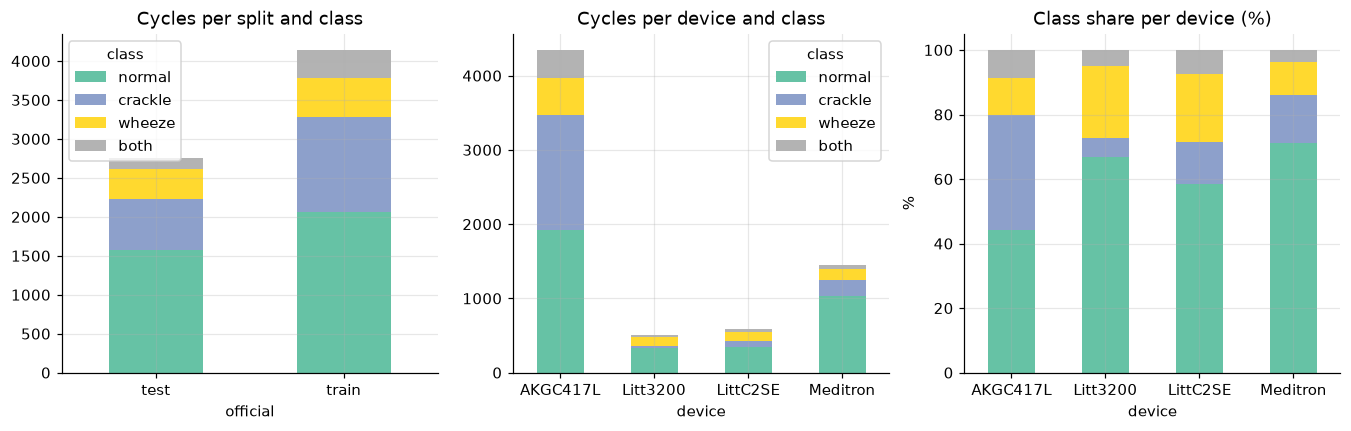

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
pd.crosstab(cyc.official, cyc['class'])[CLASSES].plot.bar(ax=ax[0], stacked=True, colormap='Set2', rot=0); ax[0].set_title('Cycles per split and class')
pd.crosstab(cyc.device, cyc['class'])[CLASSES].plot.bar(ax=ax[1], stacked=True, colormap='Set2', rot=0); ax[1].set_title('Cycles per device and class')
(pd.crosstab(cyc.device, cyc['class'], normalize='index')[CLASSES] * 100).plot.bar(ax=ax[2], stacked=True, colormap='Set2', rot=0, legend=False)
ax[2].set_title('Class share per device (%)'); ax[2].set_ylabel('%')
savefig(fig, FIG, 'class_balance')

Device is confounded with class mix and site: AKGC417L holds most crackle cycles, Meditron and Litt3200 are mostly normal.
This is why the AKGC417L LODO fold is class-mix dominated.

## 2. Durations, sampling rates, recording modes

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
both,506.0,3.06,1.09,0.57,2.24,2.90,3.56,8.59
crackle,1864.0,2.78,0.95,0.37,2.14,2.63,3.45,8.74
normal,3642.0,2.61,1.28,0.20,1.72,2.44,3.29,16.16
wheeze,886.0,2.70,1.14,0.23,1.80,2.58,3.36,9.22


duration                                           n_cycles                                       
            count  mean   std   min   25%   50%   75%   max    count  mean  std  min  25%   50%   75%   max
device                                                                                                     
AKGC417L    646.0  20.0   0.0  20.0  20.0  20.0  20.0  20.0    646.0   6.7  2.2  2.0  5.0   6.0   8.0  16.0
Litt3200     60.0  19.7   5.6   7.9  16.1  18.8  23.0  30.0     60.0   8.4  3.1  3.0  6.8   8.0  10.0  17.0
LittC2SE     87.0  20.0   0.0  20.0  20.0  20.0  20.0  20.0     87.0   6.8  1.9  4.0  5.0   6.0   8.5  11.0
Meditron    127.0  30.9  19.6  19.8  20.0  20.0  32.9  86.2    127.0  11.5  5.5  3.0  7.5  10.0  15.0  33.0

cycles longer than 5 s (cut by the model): 3.4%


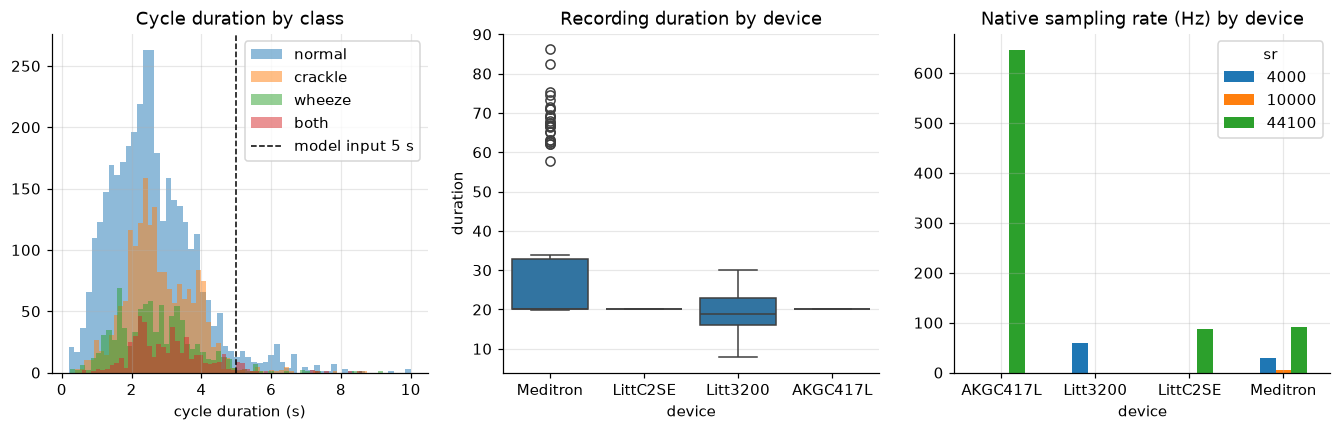

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for c in CLASSES:
    ax[0].hist(cyc[cyc['class'] == c].dur.clip(0, 10), bins=60, alpha=0.5, label=c)
ax[0].axvline(5, color='k', ls='--', lw=1, label='model input 5 s'); ax[0].set_xlabel('cycle duration (s)'); ax[0].legend(); ax[0].set_title('Cycle duration by class')
sns.boxplot(data=rec, x='device', y='duration', ax=ax[1]); ax[1].set_title('Recording duration by device')
pd.crosstab(rec.device, rec.sr).plot.bar(ax=ax[2], rot=0); ax[2].set_title('Native sampling rate (Hz) by device')
savefig(fig, FIG, 'durations_rates')
display(cyc.groupby('class').dur.describe(), rec.groupby('device')[['duration', 'n_cycles']].describe().round(1))
print('cycles longer than 5 s (cut by the model):', f"{(cyc.dur > 5).mean():.1%}")

## 3. Patients: diagnosis, demographics, chest location

diagnosis
COPD              64
Healthy           26
URTI              14
Bronchiectasis     7
Pneumonia          6
Bronchiolitis      6
LRTI               2
Asthma             1
Name: count, dtype: int64

devices
Meditron             61
AKGC417L             31
LittC2SE             21
Litt3200              9
Litt3200,Meditron     2
AKGC417L,LittC2SE     1
LittC2SE,Meditron     1
Name: count, dtype: int64

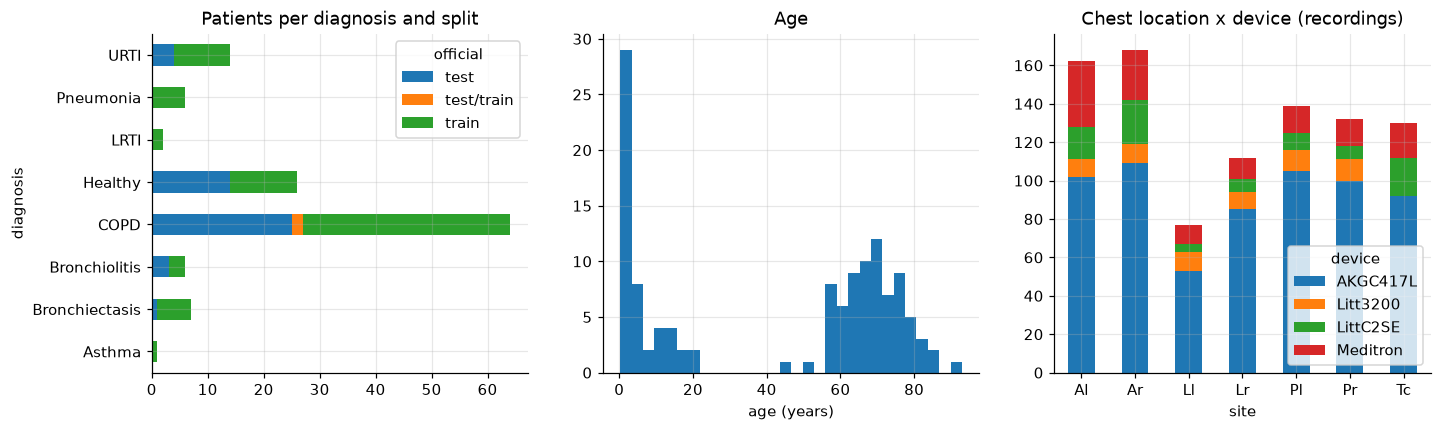

In [5]:
diag = pd.read_csv(ICBHI / 'patient_diagnosis.txt', sep='\t', header=None, names=['patient', 'diagnosis'], dtype=str)
meta = pd.read_csv(ICBHI / 'metadata.txt', sep='\t', header=None, names=['patient', 'age', 'sex', 'adult_bmi', 'child_weight', 'child_height', 'location'], dtype={'patient': str}, na_values='NA')
pt = rec.groupby('patient').agg(official=('official', lambda s: '/'.join(sorted(set(s)))), devices=('device', lambda s: ','.join(sorted(set(s)))),
                                n_rec=('device', 'size'), abnormal=('abnormal', 'max')).join(diag.set_index('patient')).join(meta.set_index('patient')[['age', 'sex']])
pt.to_csv(TAB / 'patients.csv')
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
pd.crosstab(pt.diagnosis, pt.official).plot.barh(ax=ax[0], stacked=True); ax[0].set_title('Patients per diagnosis and split')
ax[1].hist(pt.age.dropna(), bins=30); ax[1].set_xlabel('age (years)'); ax[1].set_title('Age')
pd.crosstab(rec.site, rec.device).plot.bar(ax=ax[2], stacked=True, rot=0); ax[2].set_title('Chest location x device (recordings)')
savefig(fig, FIG, 'patients')
display(pt.diagnosis.value_counts(), pt.devices.value_counts())

## 4. Device spectra (why spectrum correction)

Mean magnitude spectrum per device (STFT 1024 / 512 at 16 kHz, the SC front end), 40 recordings per device.

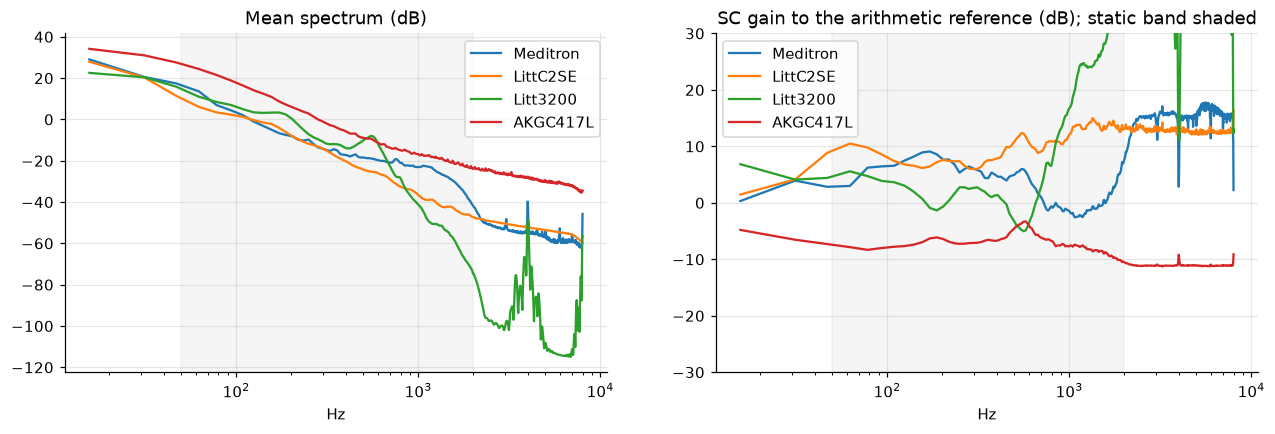

In [6]:
from src.processing.audio import load_wav
from src.processing.correction import mean_spectrum
rng = np.random.default_rng(0)
spec = {}
for d in DEVICES:
    stems = rec[rec.device == d].index.to_numpy()
    spec[d] = mean_spectrum([load_wav(ICBHI / 'audio_test_data' / f'{s}.wav') for s in rng.choice(stems, min(40, len(stems)), replace=False)])
f = np.fft.rfftfreq(1024, 1 / 16000)
ref = np.mean([spec[d] for d in DEVICES], 0)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for d in DEVICES:
    ax[0].semilogx(f[1:], 20 * np.log10(spec[d][1:]), label=d)
    ax[1].semilogx(f[1:], 20 * np.log10(ref[1:] / spec[d][1:]), label=d)
for a in ax: a.axvspan(50, 2000, color='grey', alpha=0.08); a.set_xlabel('Hz'); a.legend()
ax[0].set_title('Mean spectrum (dB)'); ax[1].set_title('SC gain to the arithmetic reference (dB); static band shaded')
ax[1].set_ylim(-30, 30)
savefig(fig, FIG, 'device_spectra')
np.savez(TAB / 'device_spectra.npz', freqs=f, **spec)

## 5. Example cycles (waveform and log-mel)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/eda/example_cycles.png')

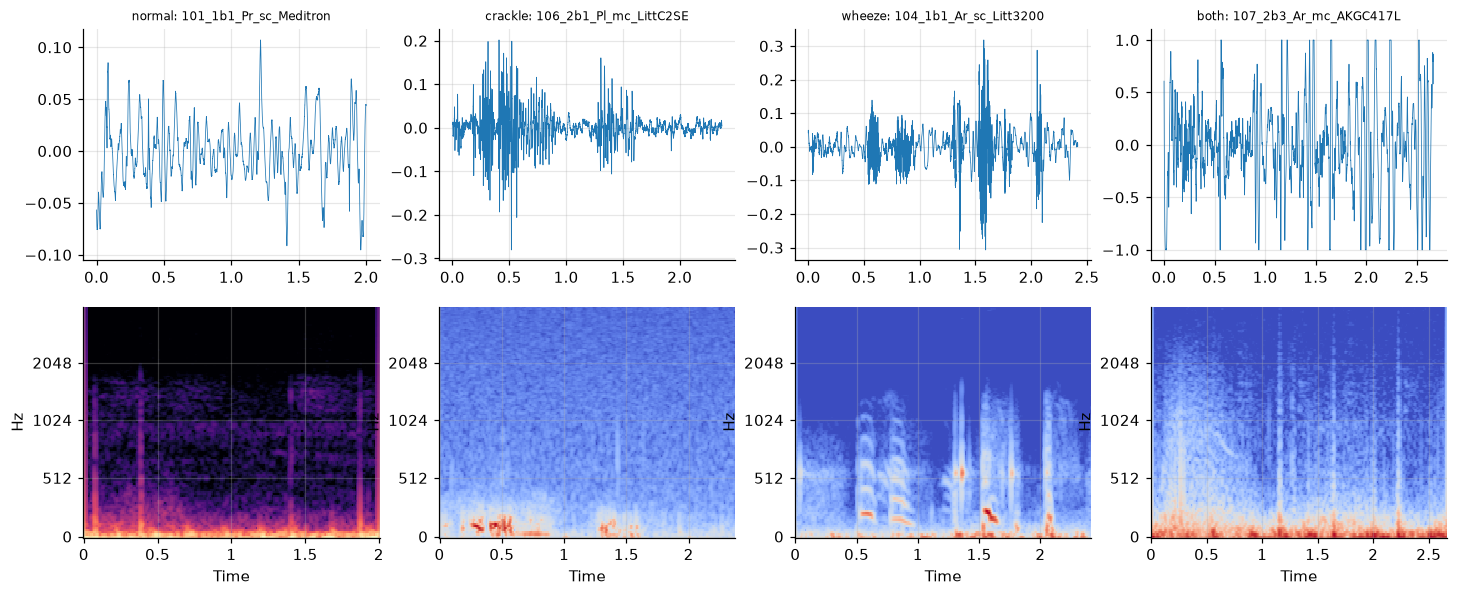

In [7]:
import librosa, librosa.display
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for i, c in enumerate(CLASSES):
    r = cyc[(cyc['class'] == c) & (cyc.dur.between(2, 4))].iloc[3]
    x = load_wav(r.wav)[int(r.start * 16000): int(r.end * 16000)]
    ax[0, i].plot(np.arange(len(x)) / 16000, x, lw=0.5); ax[0, i].set_title(f'{c}: {r.stem}', fontsize=8)
    m = librosa.power_to_db(librosa.feature.melspectrogram(y=x, sr=16000, n_fft=1024, hop_length=160, n_mels=128, fmax=4000))
    librosa.display.specshow(m, sr=16000, hop_length=160, x_axis='time', y_axis='mel', fmax=4000, ax=ax[1, i])
savefig(fig, FIG, 'example_cycles')

## 6. LODO cohorts (held-out device = test; train on the rest)

In [8]:
rows = []
for d in DEVICES:
    held = cyc[cyc.device == d]
    rows.append(dict(held_out=d, test_cycles=len(held), test_patients=held.patient.nunique(),
                     **{f'test_{c}': (held['class'] == c).mean() * 100 for c in CLASSES},
                     train_pool_cycles=(cyc.device != d).sum()))
lodo = pd.DataFrame(rows).set_index('held_out'); lodo.to_csv(TAB / 'lodo_cohorts.csv'); display(lodo)

,test_cycles,test_patients,test_normal,test_crackle,test_wheeze,test_both,train_pool_cycles
held_out,,,,,,,
Meditron,1456,64,71.22,14.77,10.16,3.85,5442
LittC2SE,594,23,58.42,12.96,21.21,7.41,6304
Litt3200,502,11,66.93,5.78,22.31,4.98,6396
AKGC417L,4346,32,44.22,35.50,11.50,8.77,2552


## 7. KAUH (external, vendor filters of the same recordings)

,stem,wav,patient,filter,diagnosis,sound,site,age,sex,label
0,"BP100_N,N,P R M,70,F",/home/namdp15/Workspace/Personal/KHKT-CVA-2026...,kauh_P100,Bell,n,N,P R M,70,F,0
1,"BP101_Asthma,E W,P L M,12,F",/home/namdp15/Workspace/Personal/KHKT-CVA-2026...,kauh_P101,Bell,asthma,E W,P L M,12,F,2
2,"BP102_N,N,P L L,41,M",/home/namdp15/Workspace/Personal/KHKT-CVA-2026...,kauh_P102,Bell,n,N,P L L,41,M,0


filter        3
label         5
sound         9
diagnosis    11
dtype: int64


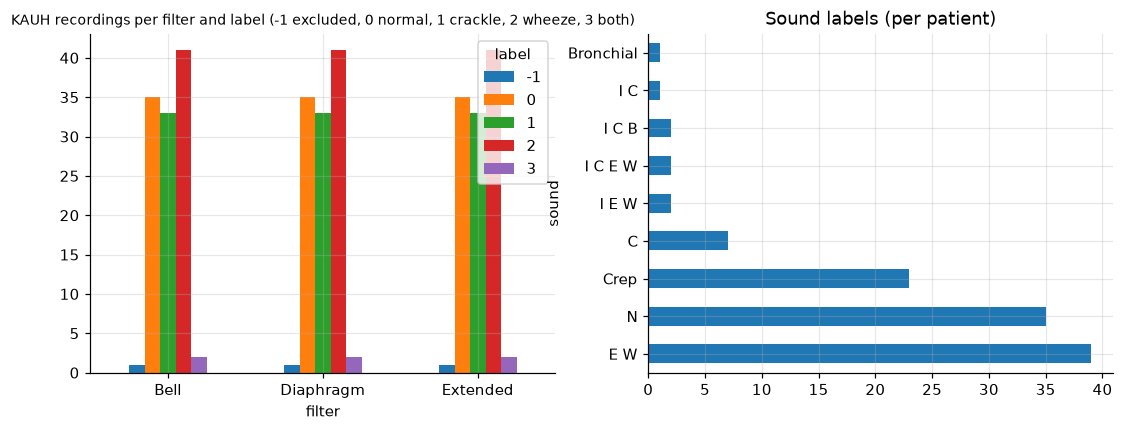

In [9]:
k = file_table(DATA / 'raw' / 'kauh')
k.to_csv(TAB / 'kauh_files.csv', index=False)
display(k.head(3))
cols = [c for c in ['filter', 'label', 'sound', 'diagnosis'] if c in k.columns]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
if 'filter' in k and 'label' in k:
    pd.crosstab(k['filter'], k['label']).plot.bar(ax=ax[0], rot=0); ax[0].set_title('KAUH recordings per filter and label (-1 excluded, 0 normal, 1 crackle, 2 wheeze, 3 both)', fontsize=9)
if 'sound' in k:
    k.drop_duplicates('patient')['sound'].value_counts().head(12).plot.barh(ax=ax[1]); ax[1].set_title('Sound labels (per patient)')
savefig(fig, FIG, 'kauh')
print(k[cols].nunique())

## 8. Replay set (speaker -> phone / electret)

In [10]:
R = DATA / 'raw' / 'phantom_replay'
rp = pd.DataFrame([dict(capture=p.parent.name, stem=p.stem.rsplit('_', 1)[0], sr=sf.info(p).samplerate, sec=sf.info(p).duration)
                   for c in ['phone', 'electret'] for p in sorted((R / c).glob('*.wav'))])
rp = rp.join(rec[['patient', 'device', 'official', 'n_cycles', 'abnormal']], on='stem')
rp.to_csv(TAB / 'replay_takes.csv', index=False)
display(rp.groupby('capture').agg(takes=('stem', 'size'), sr=('sr', 'first'), sec_mean=('sec', 'mean')),
        rp[rp.capture == 'phone'].groupby(['official', 'device']).size().rename('recordings'),
        cyc[cyc.stem.isin(rp.stem)].groupby('official')['class'].value_counts().unstack(fill_value=0))

,takes,sr,sec_mean
capture,,,
electret,20,48000,24.40
phone,20,48000,23.06


official  device  
test      Litt3200    6
          Meditron    3
train     AKGC417L    7
          LittC2SE    3
          Meditron    1
Name: recordings, dtype: int64

class,both,crackle,normal,wheeze
official,,,,
test,0,1,80,10
train,10,36,31,11
